# Важливість ознак автомобілів

Мережко Олександр

Порівнюю взаємну інформацію та важливість ознак у випадковому лісі

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_regression
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

url = ('https://raw.githubusercontent.com/goitacademy/MACHINE-LEARNING-NEO/'
       'main/datasets/mod_05_topic_10_various_data.pkl')
autos = pd.read_pickle(url)['autos'].copy()
print('Розмір:', autos.shape)
print('Пропусків:', autos.isna().sum().sum())
autos.head()

Розмір: (193, 24)
Пропусків: 0


,make,fuel_type,aspiration,num_of_doors,body_style,drive_wheels,engine_location,wheel_base,length,width,...,engine_size,fuel_system,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price
0,alfa-romero,gas,std,2,convertible,rwd,front,88.6,168.8,64.1,...,130,mpfi,3.47,2.68,9,111,5000,21,27,13495
1,alfa-romero,gas,std,2,convertible,rwd,front,88.6,168.8,64.1,...,130,mpfi,3.47,2.68,9,111,5000,21,27,16500
2,alfa-romero,gas,std,2,hatchback,rwd,front,94.5,171.2,65.5,...,152,mpfi,2.68,3.47,9,154,5000,19,26,16500
3,audi,gas,std,4,sedan,fwd,front,99.8,176.6,66.2,...,109,mpfi,3.19,3.40,10,102,5500,24,30,13950
4,audi,gas,std,4,sedan,4wd,front,99.4,176.6,66.4,...,136,mpfi,3.19,3.40,8,115,5500,18,22,17450


## Ознаки

Дискретними вважаю категорії, кількість дверей і циліндрів. Інші числові ознаки залишаю неперервними, навіть якщо вони записані цілими числами

In [2]:
X = autos.drop(columns='price')
y = autos['price']
cat_columns = X.select_dtypes(exclude='number').columns.tolist()
num_columns = X.select_dtypes(include='number').columns.tolist()
discrete_columns = cat_columns + ['num_of_doors', 'num_of_cylinders']
print('Дискретні ознаки:', discrete_columns)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print('Навчання:', X_train.shape, 'Тест:', X_test.shape)

Дискретні ознаки: ['make', 'fuel_type', 'aspiration', 'body_style', 'drive_wheels', 'engine_location', 'engine_type', 'fuel_system', 'num_of_doors', 'num_of_cylinders']
Навчання: (154, 23) Тест: (39, 23)


## Взаємна інформація

Для MI кодування категорій — це просто мітки. Обидва показники розраховую на навчальній вибірці

In [3]:
X_mi = X_train.copy()
for column in cat_columns:
    X_mi[column], _ = pd.factorize(X_mi[column])

mi = pd.Series(
    mutual_info_regression(
        X_mi, y_train,
        discrete_features=X_mi.columns.isin(discrete_columns), random_state=42
    ), index=X.columns, name='MI'
)
mi.sort_values(ascending=False).head(8).round(3)

curb_weight    0.900
horsepower     0.871
engine_size    0.819
highway_mpg    0.804
city_mpg       0.679
width          0.676
length         0.604
wheel_base     0.597
Name: MI, dtype: float64

## Випадковий ліс

Для моделі використовую OneHotEncoder. Важливість усіх закодованих категорій однієї ознаки додаю разом

In [4]:
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
train_cat = encoder.fit_transform(X_train[cat_columns])
test_cat = encoder.transform(X_test[cat_columns])
train_encoded = np.hstack([X_train[num_columns], train_cat])
test_encoded = np.hstack([X_test[num_columns], test_cat])

model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(train_encoded, y_train)
pred = model.predict(test_encoded)
print(f'MAE: {mean_absolute_error(y_test, pred):.0f}')
print(f'R²: {r2_score(y_test, pred):.2f}')

original_columns = num_columns + [
    column for column, categories in zip(cat_columns, encoder.categories_)
    for _ in categories
]
importance = pd.Series(model.feature_importances_, index=original_columns)
importance = importance.groupby(level=0).sum().rename('Random Forest')
scores = pd.concat([mi, importance], axis=1)
scores.sort_values('Random Forest', ascending=False).head(8).round(3)

MAE: 1725
R²: 0.93


,MI,Random Forest
engine_size,0.819,0.443
curb_weight,0.900,0.427
horsepower,0.871,0.021
width,0.676,0.020
make,0.473,0.014
city_mpg,0.679,0.014
highway_mpg,0.804,0.011
length,0.604,0.007


## Порівняння

Переводжу обидва показники у відносні ранги: більше значення означає вищу позицію

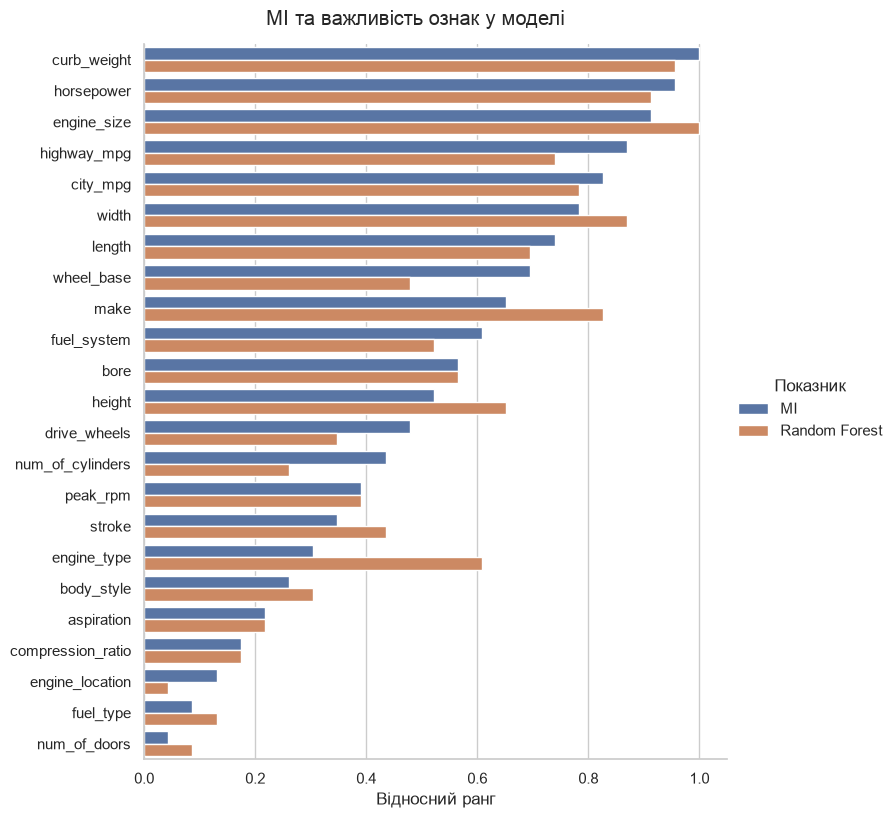

,MI,Random Forest,Різниця
engine_type,0.30,0.61,0.30
wheel_base,0.70,0.48,0.22
make,0.65,0.83,0.17
num_of_cylinders,0.43,0.26,0.17
height,0.52,0.65,0.13


In [5]:
ranks = scores.rank(pct=True).sort_values('MI', ascending=False)
plot_data = ranks.rename_axis('Ознака').reset_index().melt(
    id_vars='Ознака', var_name='Показник', value_name='Ранг'
)
sns.set_theme(style='whitegrid')
g = sns.catplot(
    data=plot_data, x='Ранг', y='Ознака', hue='Показник', kind='bar',
    height=8, aspect=1, palette=['#4c72b0', '#dd8452']
)
g.set(xlim=(0, 1.05))
g.set_axis_labels('Відносний ранг', '')
g.fig.suptitle('MI та важливість ознак у моделі', y=1.02)
plt.show()

ranks.assign(Різниця=(ranks['MI'] - ranks['Random Forest']).abs()).sort_values(
    'Різниця', ascending=False
).head(5).round(2)

## Висновок

За MI перше місце займає curb_weight, а у випадковому лісі — engine_size. У engine_type позиція в моделі помітно вища, ніж за MI

MI оцінює зв’язок окремої ознаки з ціною, а ліс використовує ознаки разом. Тому не варто одразу видаляти ознаку через низький MI. Отримані ранги стосуються цієї моделі, а не всіх можливих моделей